In [1]:
import os
import time
import joblib
import numpy as np
import pandas as pd
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer, SimpleImputer
from sklearn.neural_network import MLPRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    HistGradientBoostingRegressor,
)
from sklearn.linear_model import RidgeCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import kagglehub


In [2]:
# DATA PREPARATION & MISSINGNESS SIMULATION

import glob
DATA_DIR = os.path.dirname(glob.glob('/kaggle/input/**/2025.csv', recursive=True)[0])
print('Data folder:', DATA_DIR)
df_raw = pd.concat([pd.read_csv(os.path.join(DATA_DIR, f'{y}.csv')) for y in (2022, 2023, 2024, 2025)],
                   ignore_index=True)
df_raw.columns = df_raw.columns.str.strip()

colmap = {'PM2.5 (µg/m³)': 'PM2.5', 'PM10 (µg/m³)': 'PM10', 'CO (mg/m³)': 'CO',
          'NO2 (µg/m³)': 'NO2', 'AT (°C)': 'Temperature', 'RH (%)': 'Humidity'}
colmap = {k: v for k, v in colmap.items() if k in df_raw.columns and df_raw[k].notna().any()}
pollutants = list(colmap.values())
print('Variables:', pollutants)

df_raw['Timestamp'] = pd.to_datetime(df_raw['Timestamp'])
df = df_raw.set_index('Timestamp').sort_index()[list(colmap)].rename(columns=colmap)
df = df[~df.index.duplicated()].apply(pd.to_numeric, errors='coerce').asfreq('15min')
observed = df.notna()

train, train_obs = df.loc['2023':'2024'], observed.loc['2023':'2024']
test, test_obs = df.loc['2025':'2025'], observed.loc['2025':'2025']
warm = df.loc[test.index[0] - pd.Timedelta('3D'): test.index[0] - pd.Timedelta('15min')]

os.makedirs('models', exist_ok=True)
os.makedirs('results', exist_ok=True)

time_cols = ['Month', 'DayOfYear', 'DayOfWeek', 'doy_sin', 'doy_cos', 'hour_sin', 'hour_cos']
hist_cols = [f'{k}_{p}' for p in pollutants for k in ('last', 'age', 'med1h', 'med3h')]
ctx_cols = time_cols + hist_cols
cur_cols = [f'cur_{p}' for p in pollutants]


def make_features(frame):
    F = pd.DataFrame(index=frame.index)
    F['Month'] = frame.index.month
    F['DayOfYear'] = frame.index.dayofyear
    F['doy_sin'] = np.sin(2 * np.pi * frame.index.dayofyear / 365.0)
    F['doy_cos'] = np.cos(2 * np.pi * frame.index.dayofyear / 365.0)
    F['DayOfWeek'] = frame.index.dayofweek
    h = frame.index.hour + frame.index.minute / 60.0
    F['hour_sin'] = np.sin(2 * np.pi * h / 24)
    F['hour_cos'] = np.cos(2 * np.pi * h / 24)
    for p in pollutants:
        s = frame[p]
        F[f'cur_{p}'] = s
        prev = s.shift(1)
        t_obs = pd.Series(np.where(prev.notna(), frame.index.values, np.datetime64('NaT')),
                          index=frame.index).ffill()
        age = (frame.index.to_series() - t_obs).dt.total_seconds() / 3600.0
        stale = age.isna() | (age > 48)
        F[f'last_{p}'] = prev.ffill().where(~stale)
        F[f'age_{p}'] = age.where(~stale, 48.0)
        F[f'med1h_{p}'] = s.rolling('1h', closed='left').median()
        F[f'med3h_{p}'] = s.rolling('3h', closed='left').median()
    return F


GROUPS = {'PMS': ['PM2.5', 'PM10'], 'MQ135': ['NO2'], 'MQ7': ['CO'], 'DHT': ['Temperature', 'Humidity']}
GROUPS = {g: [c for c in cols if c in pollutants] for g, cols in GROUPS.items()}
GROUPS = {g: cols for g, cols in GROUPS.items() if cols}
DURATION = {'1h': 4, '6h': 24, '24h': 96}
PATTERNS = ['G1_10', 'G1_20', 'G1_30'] + [f'G2_{g}_{d}' for g in GROUPS for d in DURATION] + ['G3_10']


def make_mask(frame, obs, pattern, seed):
    rng = np.random.default_rng(seed)
    n = len(frame)
    if pattern == 'TRAIN_MIX':
        m = make_mask(frame, obs, 'G1_20', seed * 100 + 1)
        for i, g in enumerate(GROUPS):
            m |= make_mask(frame, obs, f'G2_{g}_6h', seed * 100 + 2 + i)
        m |= make_mask(frame, obs, 'G3_10', seed * 100 + 9)
    elif pattern.startswith('G1'):
        m = pd.DataFrame(rng.random((n, len(pollutants))) < int(pattern.split('_')[1]) / 100,
                         index=frame.index, columns=pollutants)
    elif pattern.startswith('G2'):
        _, g, d = pattern.split('_')
        L = DURATION[d]
        starts = np.arange(int(rng.integers(L)), n - L + 1, L)
        rows = np.zeros(n, dtype=bool)
        for s in rng.choice(starts, size=min(len(starts), max(1, round(0.10 * n / L))), replace=False):
            rows[s:s + L] = True
        m = pd.DataFrame(False, index=frame.index, columns=pollutants)
        m.loc[rows, GROUPS[g]] = True
    else:
        rows = rng.random(n) < int(pattern.split('_')[1]) / 100
        m = pd.DataFrame(np.repeat(rows[:, None], len(pollutants), axis=1), index=frame.index, columns=pollutants)
    return m & obs


train_mask = make_mask(train, train_obs, 'TRAIN_MIX', 102)
train_missing = train.mask(train_mask)
F_train = make_features(train_missing)


def evaluate_imputation(df_imp, df_true, mask_df):
    r2_scores, mae_scores, rmse_scores = {}, {}, {}
    all_true, all_pred = [], []
    for p in pollutants:
        m = mask_df[p]
        if m.sum() < 10:
            continue
        y_true = df_true.loc[m, p].values
        y_pred = df_imp.loc[m, p].values
        r2_scores[p] = r2_score(y_true, y_pred)
        mae_scores[p] = mean_absolute_error(y_true, y_pred)
        rmse_scores[p] = np.sqrt(mean_squared_error(y_true, y_pred))
        all_true.extend(y_true)
        all_pred.extend(y_pred)

    overall = {
        'Mean R2': np.mean(list(r2_scores.values())),
        'Mean MAE': mean_absolute_error(all_true, all_pred),
        'Mean RMSE': np.sqrt(mean_squared_error(all_true, all_pred))
    }
    return overall, r2_scores, mae_scores, rmse_scores


def filled(model):
    return make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), model)

Data folder: /kaggle/input/datasets/samanawaya/dataset-test
Variables: ['PM2.5', 'PM10', 'CO', 'NO2', 'Temperature', 'Humidity']


In [3]:
# DYNAMIC IMPUTATION BASELINE

start_dyn = time.time()

CO_COLS = ['last_CO', 'age_CO', 'med1h_CO', 'med3h_CO', 'hour_sin', 'hour_cos',
           'cur_PM2.5', 'cur_PM10', 'cur_NO2', 'cur_Temperature', 'cur_Humidity']


def get_pass1_model(p):
    if p in ['PM2.5', 'PM10']:
        return filled(MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=500, random_state=42))
    elif p == 'CO':
        return filled(KNeighborsRegressor(n_neighbors=204, weights='distance', p=1))
    else:
        return filled(RandomForestRegressor(n_estimators=100, max_depth=16, min_samples_leaf=10,
                                            n_jobs=-1, random_state=42))


def pass2_input(F, pass1_preds, p):
    X = F[ctx_cols].copy()
    for o in pollutants:
        if o != p:
            X[f'cur_{o}'] = F[f'cur_{o}'].fillna(pass1_preds[o])
    return X


def dyn_cols(p, cols, co_cols):
    return [c for c in cols if c in co_cols] if p == 'CO' else list(cols)


dyn_model = {'pass1': {}, 'pass2': {}, 'co_cols': CO_COLS}
for p in pollutants:
    rows = train[p].notna()
    dyn_model['pass1'][p] = get_pass1_model(p).fit(F_train.loc[rows, dyn_cols(p, ctx_cols, CO_COLS)],
                                                   train.loc[rows, p])
pass1_preds = pd.DataFrame({p: dyn_model['pass1'][p].predict(F_train[dyn_cols(p, ctx_cols, CO_COLS)])
                            for p in pollutants}, index=F_train.index)

for p in pollutants:
    rows = train[p].notna()
    X2 = pass2_input(F_train, pass1_preds, p)
    dyn_model['pass2'][p] = get_pass1_model(p).fit(X2.loc[rows, dyn_cols(p, X2.columns, CO_COLS)],
                                                   train.loc[rows, p])

time_dyn = time.time() - start_dyn
joblib.dump(dyn_model, 'models/dynamic_imputation.joblib')


def predict_dynamic(frame, model):
    F = make_features(frame)
    pass1_preds = pd.DataFrame({p: model['pass1'][p].predict(F[dyn_cols(p, ctx_cols, model['co_cols'])])
                                for p in pollutants}, index=F.index)
    out = {}
    for p in pollutants:
        X2 = pass2_input(F, pass1_preds, p)
        out[p] = model['pass2'][p].predict(X2[dyn_cols(p, X2.columns, model['co_cols'])])
    return pd.DataFrame(out, index=F.index)

In [4]:
# MICE IMPUTATION (ExtraTrees-Backed)

start_mice = time.time()

mice_pre = SimpleImputer(strategy='median').fit(F_train[ctx_cols])
mice_imputer = IterativeImputer(
    estimator=ExtraTreesRegressor(n_estimators=30, max_depth=12, min_samples_leaf=20, random_state=42, n_jobs=-1),
    max_iter=3,
    initial_strategy='mean',
    random_state=42
)
mice_imputer.fit(np.hstack([mice_pre.transform(F_train[ctx_cols]), F_train[cur_cols].values]))
mice_model = {'pre': mice_pre, 'imputer': mice_imputer}

time_mice = time.time() - start_mice
joblib.dump(mice_model, 'models/mice_extratrees.joblib')


def predict_mice(frame, model):
    F = make_features(frame)
    arr = model['imputer'].transform(np.hstack([model['pre'].transform(F[ctx_cols]), F[cur_cols].values]))
    return pd.DataFrame(arr[:, -len(pollutants):], columns=pollutants, index=F.index)

/usr/local/lib/python3.13/dist-packages/sklearn/impute/_iterative.py:895: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(


In [5]:
# ITERATIVE STACKING ENSEMBLE

start_stack = time.time()


def stack_bases():
    return [HistGradientBoostingRegressor(random_state=42),
            filled(ExtraTreesRegressor(n_estimators=50, max_depth=16, min_samples_leaf=10, random_state=42, n_jobs=-1)),
            filled(RandomForestRegressor(n_estimators=50, max_depth=16, min_samples_leaf=10, random_state=42, n_jobs=-1))]


def stack_input(F, Y, p):
    other_p = [o for o in pollutants if o != p]
    return np.hstack([F[ctx_cols].values, Y[other_p].values])


X_aug = F_train[ctx_cols]
K = 2
stack_model = {'warm': {}, 'bases': [{} for _ in range(K)], 'meta': [{} for _ in range(K)]}

Y_warm = train_missing.copy()
for p in pollutants:
    obs_idx = train_missing[p].notna()
    hgb = HistGradientBoostingRegressor(random_state=42)
    hgb.fit(X_aug[obs_idx], train_missing.loc[obs_idx, p])
    stack_model['warm'][p] = hgb
    Y_warm.loc[~obs_idx, p] = hgb.predict(X_aug[~obs_idx])

cv = TimeSeriesSplit(n_splits=5)
Y_current = Y_warm.copy()

for k in range(K):
    Y_next = Y_current.copy()
    for p in pollutants:
        m = train_missing[p].isna().values
        Z_input = stack_input(F_train, Y_current, p)

        lab = train[p].notna().values
        X_train_z = Z_input[lab]
        y_train_z = train[p].values[lab]

        preds_oof = np.full((len(y_train_z), 3), np.nan)
        for tr_i, te_i in cv.split(X_train_z):
            for j, base in enumerate(stack_bases()):
                preds_oof[te_i, j] = base.fit(X_train_z[tr_i], y_train_z[tr_i]).predict(X_train_z[te_i])
        ok = ~np.isnan(preds_oof).any(axis=1)

        meta = RidgeCV(alphas=np.logspace(-3, 3, 10))
        meta.fit(preds_oof[ok], y_train_z[ok])

        bases = [base.fit(X_train_z, y_train_z) for base in stack_bases()]
        stack_model['bases'][k][p] = bases
        stack_model['meta'][k][p] = meta

        est = meta.predict(np.column_stack([base.predict(Z_input) for base in bases]))
        est_lab = est[lab]
        est_lab[ok] = meta.predict(preds_oof[ok])
        est_lab[~ok] = Y_current[p].values[lab][~ok]
        est[lab] = est_lab
        Y_next.loc[m, p] = est[m]

    Y_current = Y_next.copy()

time_stack = time.time() - start_stack
joblib.dump(stack_model, 'models/stacking_ensemble.joblib')


def predict_stacking(frame, model):
    F = make_features(frame)
    Y_current = frame[pollutants].copy()
    for p in pollutants:
        miss = Y_current[p].isna()
        if miss.any():
            Y_current.loc[miss, p] = model['warm'][p].predict(F.loc[miss, ctx_cols])
    for k in range(len(model['meta'])):
        Y_next = Y_current.copy()
        for p in pollutants:
            m = frame[p].isna().values
            if m.any():
                Z = stack_input(F, Y_current, p)[m]
                Y_next.loc[m, p] = model['meta'][k][p].predict(
                    np.column_stack([base.predict(Z) for base in model['bases'][k][p]]))
        Y_current = Y_next.copy()
    return Y_current

In [6]:
models = {
    'Dynamic Imputation': (predict_dynamic, joblib.load('models/dynamic_imputation.joblib')),
    'MICE (ExtraTrees)': (predict_mice, joblib.load('models/mice_extratrees.joblib')),
    'Optimized Stacking Ensemble': (predict_stacking, joblib.load('models/stacking_ensemble.joblib')),
}
runtimes = {'Dynamic Imputation': time_dyn, 'MICE (ExtraTrees)': time_mice, 'Optimized Stacking Ensemble': time_stack}

rows = []
for pattern in PATTERNS:
    for seed in range(5):
        mask_df = make_mask(test, test_obs, pattern, seed)
        frame = pd.concat([warm, test.mask(mask_df)])
        for name, (predict, model) in models.items():
            df_imp = predict(frame, model).loc[test.index]
            overall, r2_s, mae_s, rmse_s = evaluate_imputation(df_imp, test, mask_df)
            rows.append({'Framework': name, 'Pattern': pattern, 'Seed': seed, **overall,
                         **{f'R2 {p}': v for p, v in r2_s.items()}})
    print('done', pattern)

results = pd.DataFrame(rows)
results.to_csv('results/test_2025_all_patterns.csv', index=False)

done G1_10
done G1_20
done G1_30
done G2_PMS_1h
done G2_PMS_6h
done G2_PMS_24h
done G2_MQ135_1h
done G2_MQ135_6h
done G2_MQ135_24h
done G2_MQ7_1h
done G2_MQ7_6h
done G2_MQ7_24h
done G2_DHT_1h
done G2_DHT_6h
done G2_DHT_24h
done G3_10


In [7]:
# COMPARATIVE SUMMARY TABLES

frameworks = list(models)
g1 = results[results['Pattern'] == 'G1_20'].groupby('Framework').mean(numeric_only=True).reindex(frameworks)

summary_df = pd.DataFrame({
    'Framework': frameworks,
    'Mean R2': g1['Mean R2'].values,
    'Mean MAE': g1['Mean MAE'].values,
    'Mean RMSE': g1['Mean RMSE'].values,
    'Runtime (s)': [runtimes[f] for f in frameworks],
})

print("\n================ OVERALL PERFORMANCE COMPARISON (2025, G1_20) ================")
print(summary_df.to_string(index=False))

pollutant_df = pd.DataFrame({'Target Pollutant': pollutants,
                             **{f: [g1.loc[f, f'R2 {p}'] for p in pollutants] for f in frameworks}})

print("\n============ POLLUTANT-WISE R2 SCORE BREAKDOWN (2025, G1_20) ============")
print(pollutant_df.to_string(index=False))

pattern_mae = results.groupby(['Pattern', 'Framework'])['Mean MAE'].mean().unstack().reindex(index=PATTERNS, columns=frameworks)
pattern_r2 = results.groupby(['Pattern', 'Framework'])['Mean R2'].mean().unstack().reindex(index=PATTERNS, columns=frameworks)

print("\n============ MEAN MAE PER GAP PATTERN (2025) ============")
print(pattern_mae.round(3).to_string())
print("\n============ MEAN R2 PER GAP PATTERN (2025) ============")
print(pattern_r2.round(3).to_string())

summary_df.to_csv('results/summary_G1_20.csv', index=False)
pollutant_df.to_csv('results/pollutant_r2_G1_20.csv', index=False)
pattern_mae.to_csv('results/mae_per_pattern.csv')
pattern_r2.to_csv('results/r2_per_pattern.csv')


================ OVERALL PERFORMANCE COMPARISON (2025, G1_20) ================
                  Framework  Mean R2  Mean MAE  Mean RMSE  Runtime (s)
         Dynamic Imputation 0.958257  2.397166   6.341077   593.363171
          MICE (ExtraTrees) 0.957059  2.159250   7.062994   204.135868
Optimized Stacking Ensemble 0.964046  2.228393   6.633938  1429.671944

============ POLLUTANT-WISE R2 SCORE BREAKDOWN (2025, G1_20) ============
Target Pollutant  Dynamic Imputation  MICE (ExtraTrees)  Optimized Stacking Ensemble
           PM2.5            0.980598           0.976016                     0.976812
            PM10            0.984238           0.981423                     0.979404
              CO            0.930771           0.971379                     0.962459
             NO2            0.872375           0.832640                     0.883880
     Temperature            0.994024           0.992629                     0.993091
        Humidity            0.987534           0.98

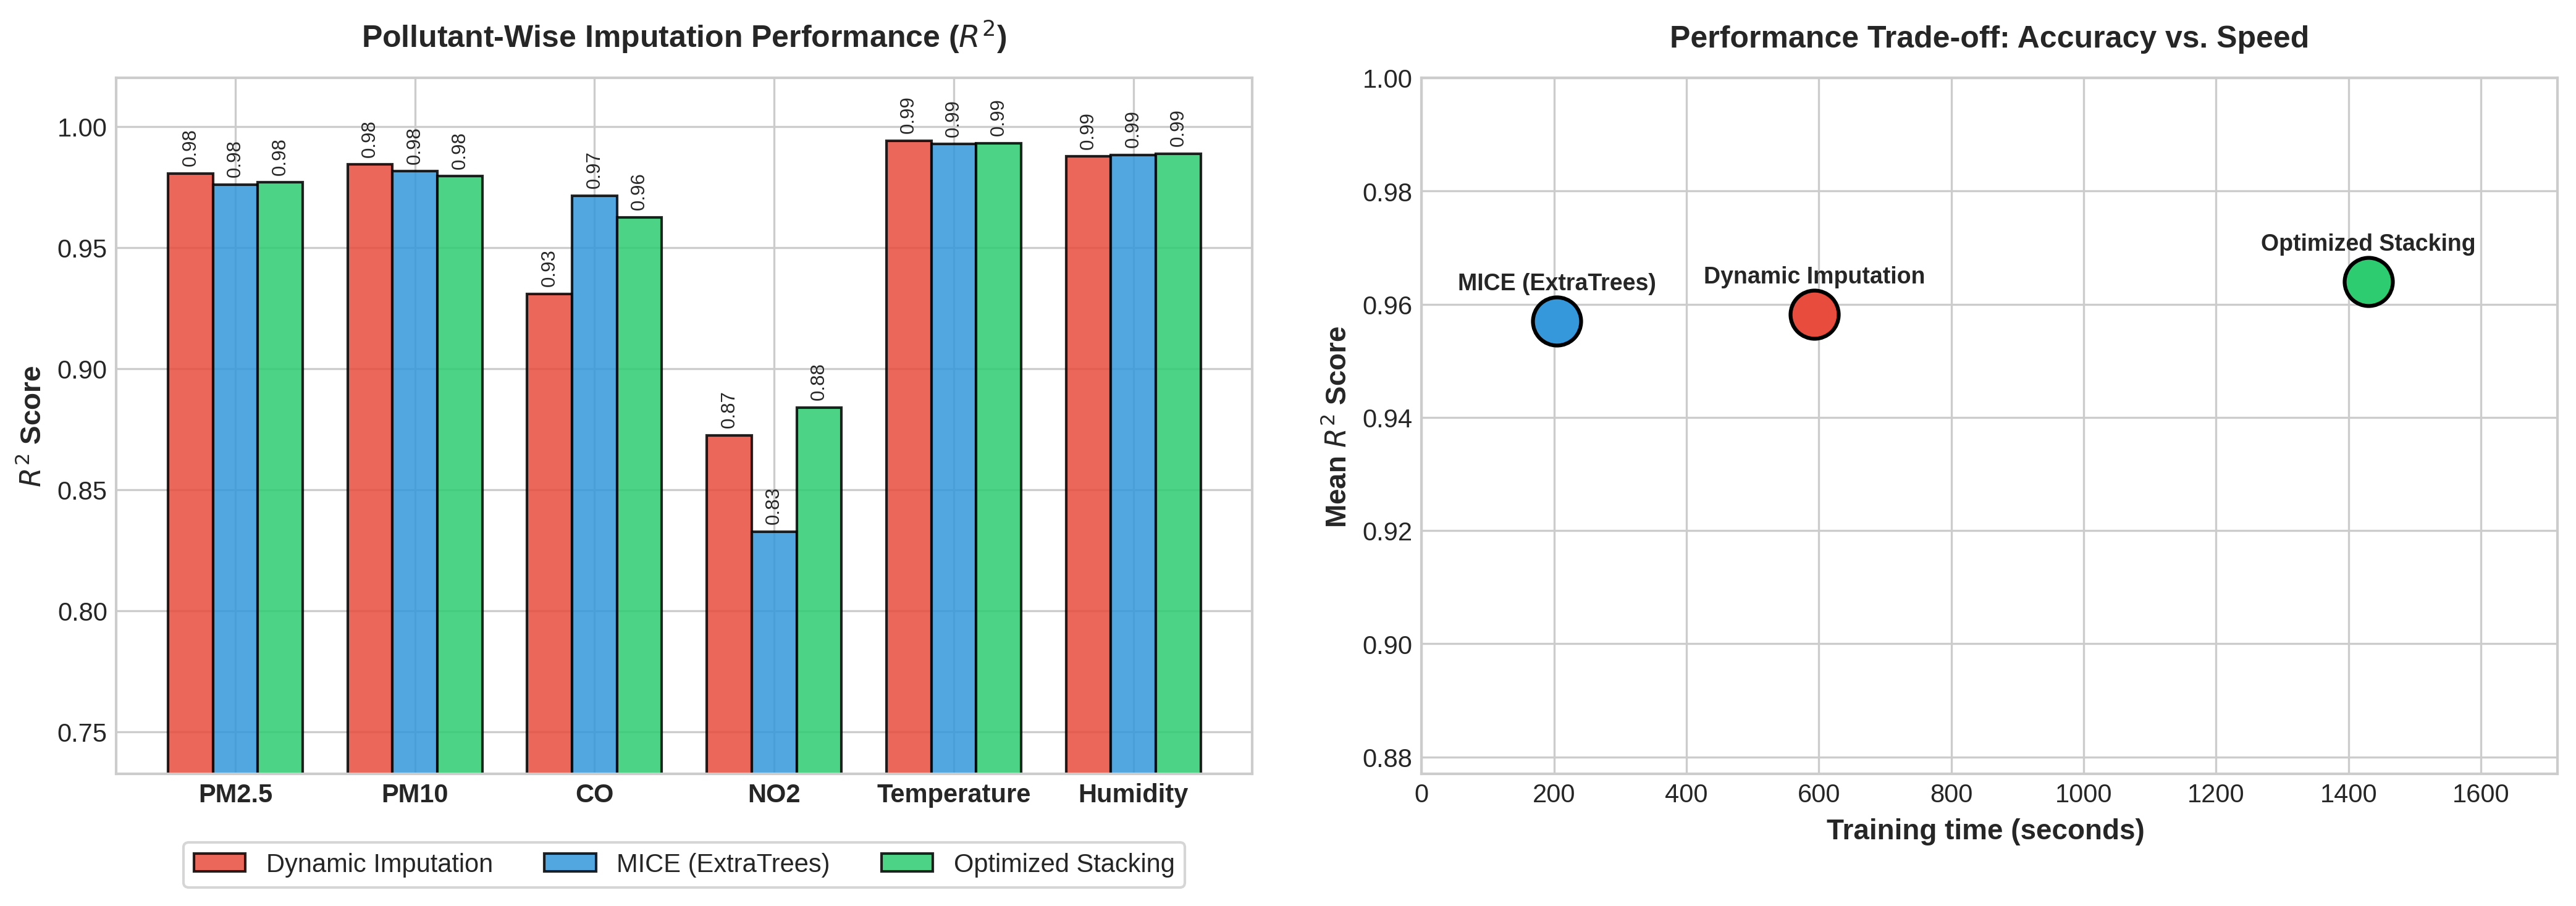

In [8]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')


frameworks = ['Dynamic Imputation', 'MICE (ExtraTrees)', 'Optimized Stacking']
r2_overall = summary_df['Mean R2'].tolist()
runtime = summary_df['Runtime (s)'].tolist()

df_pollutants = pd.DataFrame({
    'Dynamic Imputation': pollutant_df['Dynamic Imputation'].values,
    'MICE (ExtraTrees)': pollutant_df['MICE (ExtraTrees)'].values,
    'Optimized Stacking': pollutant_df['Optimized Stacking Ensemble'].values
}, index=pollutants)

fig, axes = plt.subplots(1, 2, figsize=(14, 5), dpi=300)


colors = ['#e74c3c', '#3498db', '#2ecc71']


x = np.arange(len(pollutants))
width = 0.25

for i, col in enumerate(df_pollutants.columns):
    bars = axes[0].bar(x + i*width, df_pollutants[col], width, label=col, color=colors[i], edgecolor='black', alpha=0.85)
    for bar in bars:
        height = bar.get_height()
        axes[0].annotate(f'{height:.2f}',
                         xy=(bar.get_x() + bar.get_width() / 2, height),
                         xytext=(0, 3), textcoords="offset points",
                         ha='center', va='bottom', fontsize=7.5, rotation=90)

axes[0].set_ylabel('$R^2$ Score', fontsize=11, fontweight='bold')
axes[0].set_title('Pollutant-Wise Imputation Performance ($R^2$)', fontsize=12, fontweight='bold', pad=12)
axes[0].set_xticks(x + width)
axes[0].set_xticklabels(pollutants, fontweight='bold')
axes[0].set_ylim(max(0, df_pollutants.values.min() - 0.1), 1.02)
axes[0].legend(loc='upper center', bbox_to_anchor=(0.5, -0.08), ncol=3, frameon=True)


for i in range(len(frameworks)):
    axes[1].scatter(runtime[i], r2_overall[i], s=350, color=colors[i], zorder=5, edgecolors='black', linewidth=1.5)
    axes[1].annotate(frameworks[i], (runtime[i], r2_overall[i]), textcoords="offset points",
                     xytext=(0, 12), ha='center', fontweight='bold', fontsize=9)

axes[1].set_xlabel('Training time (seconds) ', fontsize=11, fontweight='bold')
axes[1].set_ylabel('Mean $R^2$ Score ', fontsize=11, fontweight='bold')
axes[1].set_title('Performance Trade-off: Accuracy vs. Speed', fontsize=12, fontweight='bold', pad=12)
axes[1].set_xlim(0, max(runtime) * 1.2)
axes[1].set_ylim(min(r2_overall) - 0.08, min(1.0, max(r2_overall) + 0.08))

plt.tight_layout()
plt.savefig('figure1_performance_comparison.png', bbox_inches='tight')
plt.show()

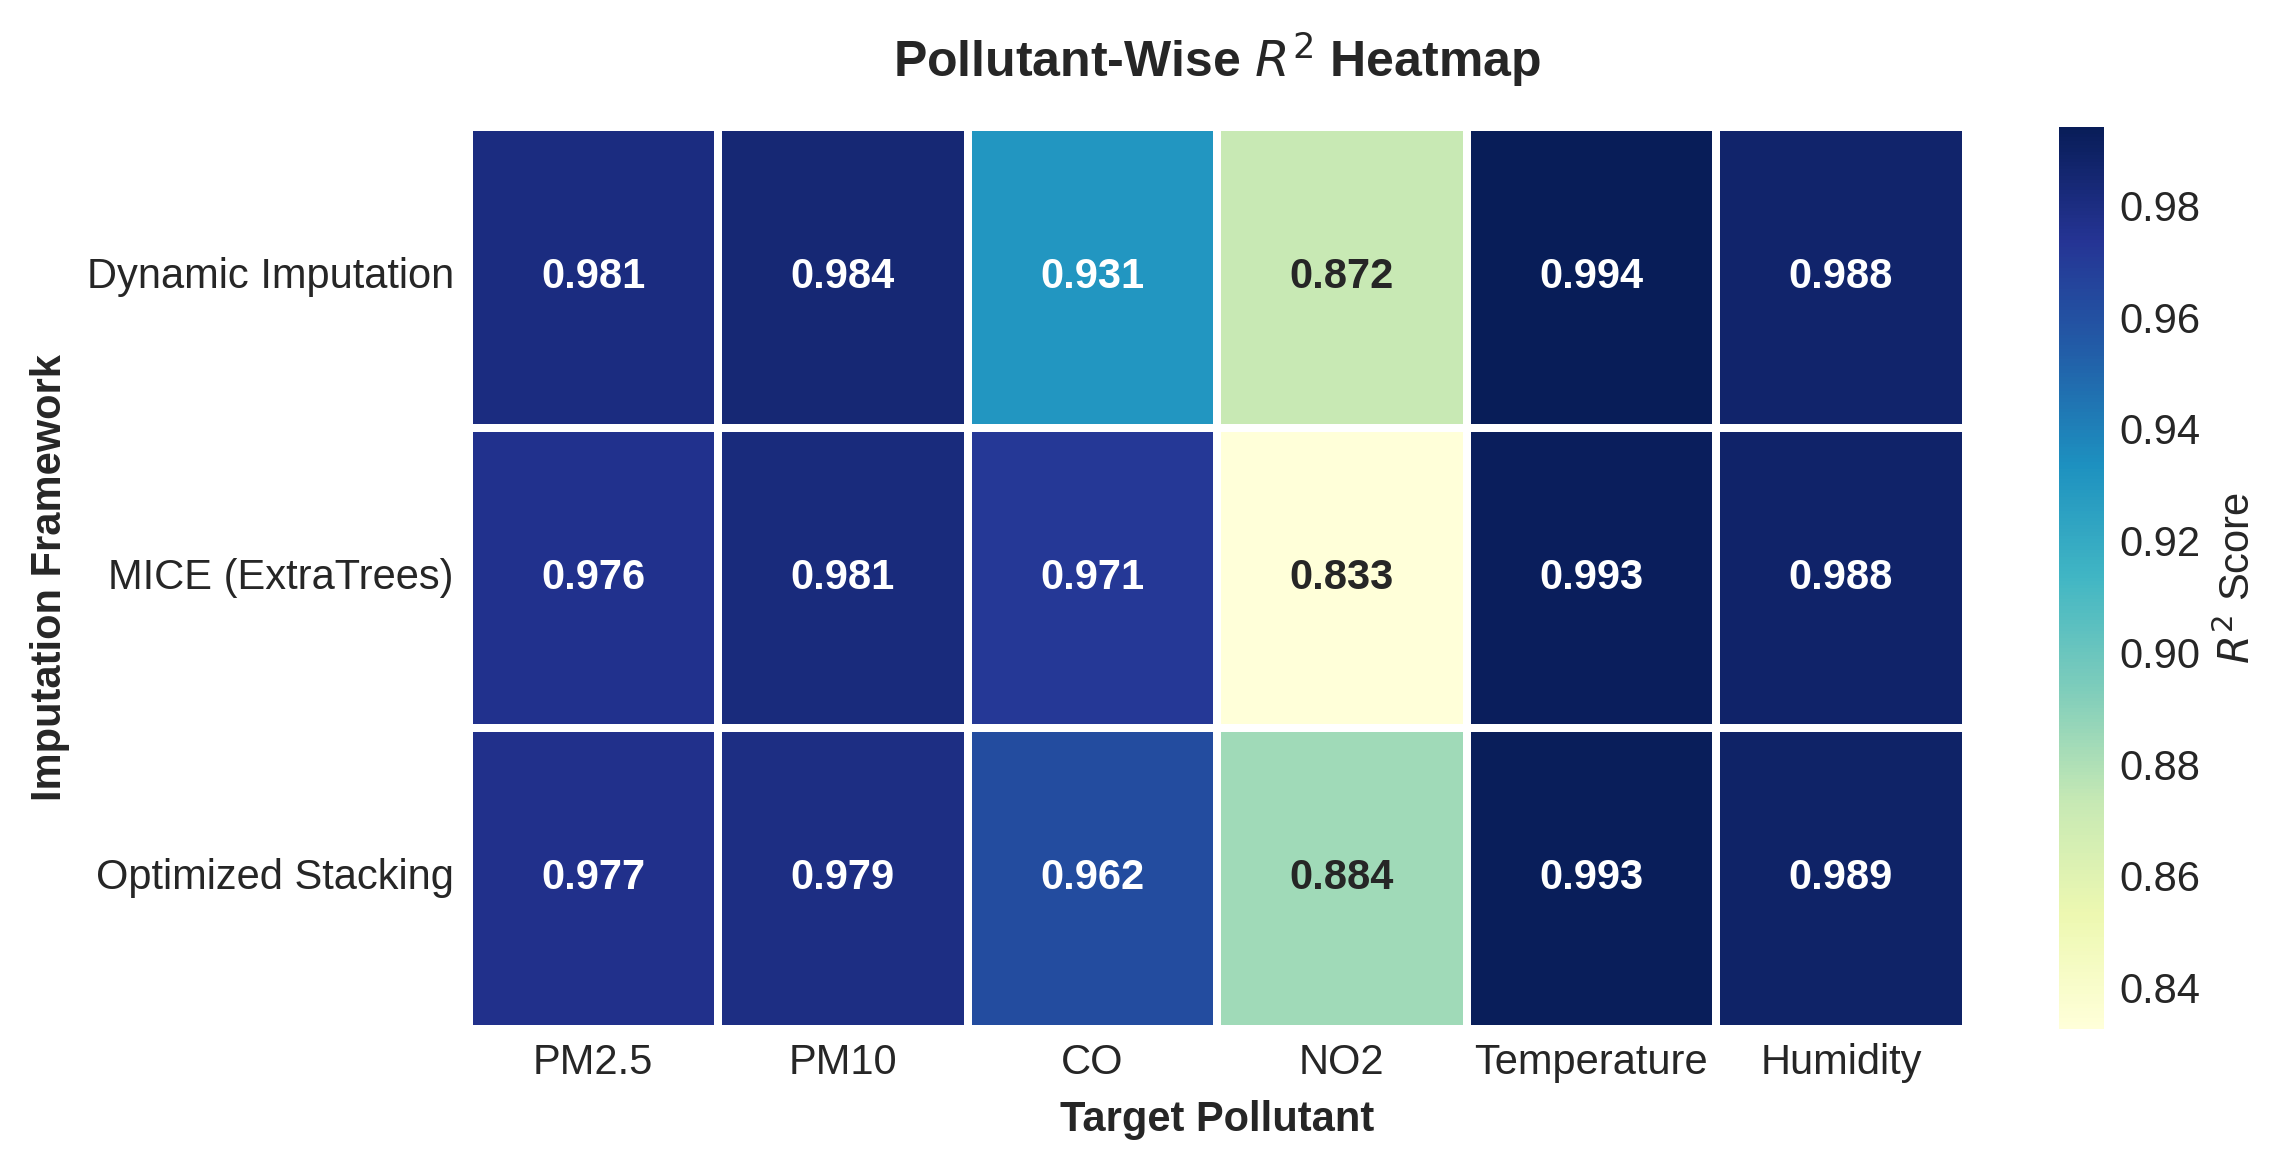

In [9]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

data_r2 = df_pollutants.T.values

df_heatmap = pd.DataFrame(data_r2,
                          index=['Dynamic Imputation', 'MICE (ExtraTrees)', 'Optimized Stacking'],
                          columns=pollutants)

fig, ax = plt.subplots(figsize=(8, 4), dpi=300)

sns.heatmap(df_heatmap, annot=True, fmt=".3f", cmap="YlGnBu", vmin=data_r2.min(), vmax=data_r2.max(),
            cbar_kws={'label': '$R^2$ Score'}, linewidths=1.5, linecolor='white', ax=ax,
            annot_kws={"size": 10, "weight": "bold"})

ax.set_title('Pollutant-Wise $R^2$ Heatmap', fontsize=12, fontweight='bold', pad=12)
ax.set_xlabel('Target Pollutant', fontsize=10, fontweight='bold')
ax.set_ylabel('Imputation Framework', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.savefig('figure2_heatmap.png', bbox_inches='tight')
plt.show()

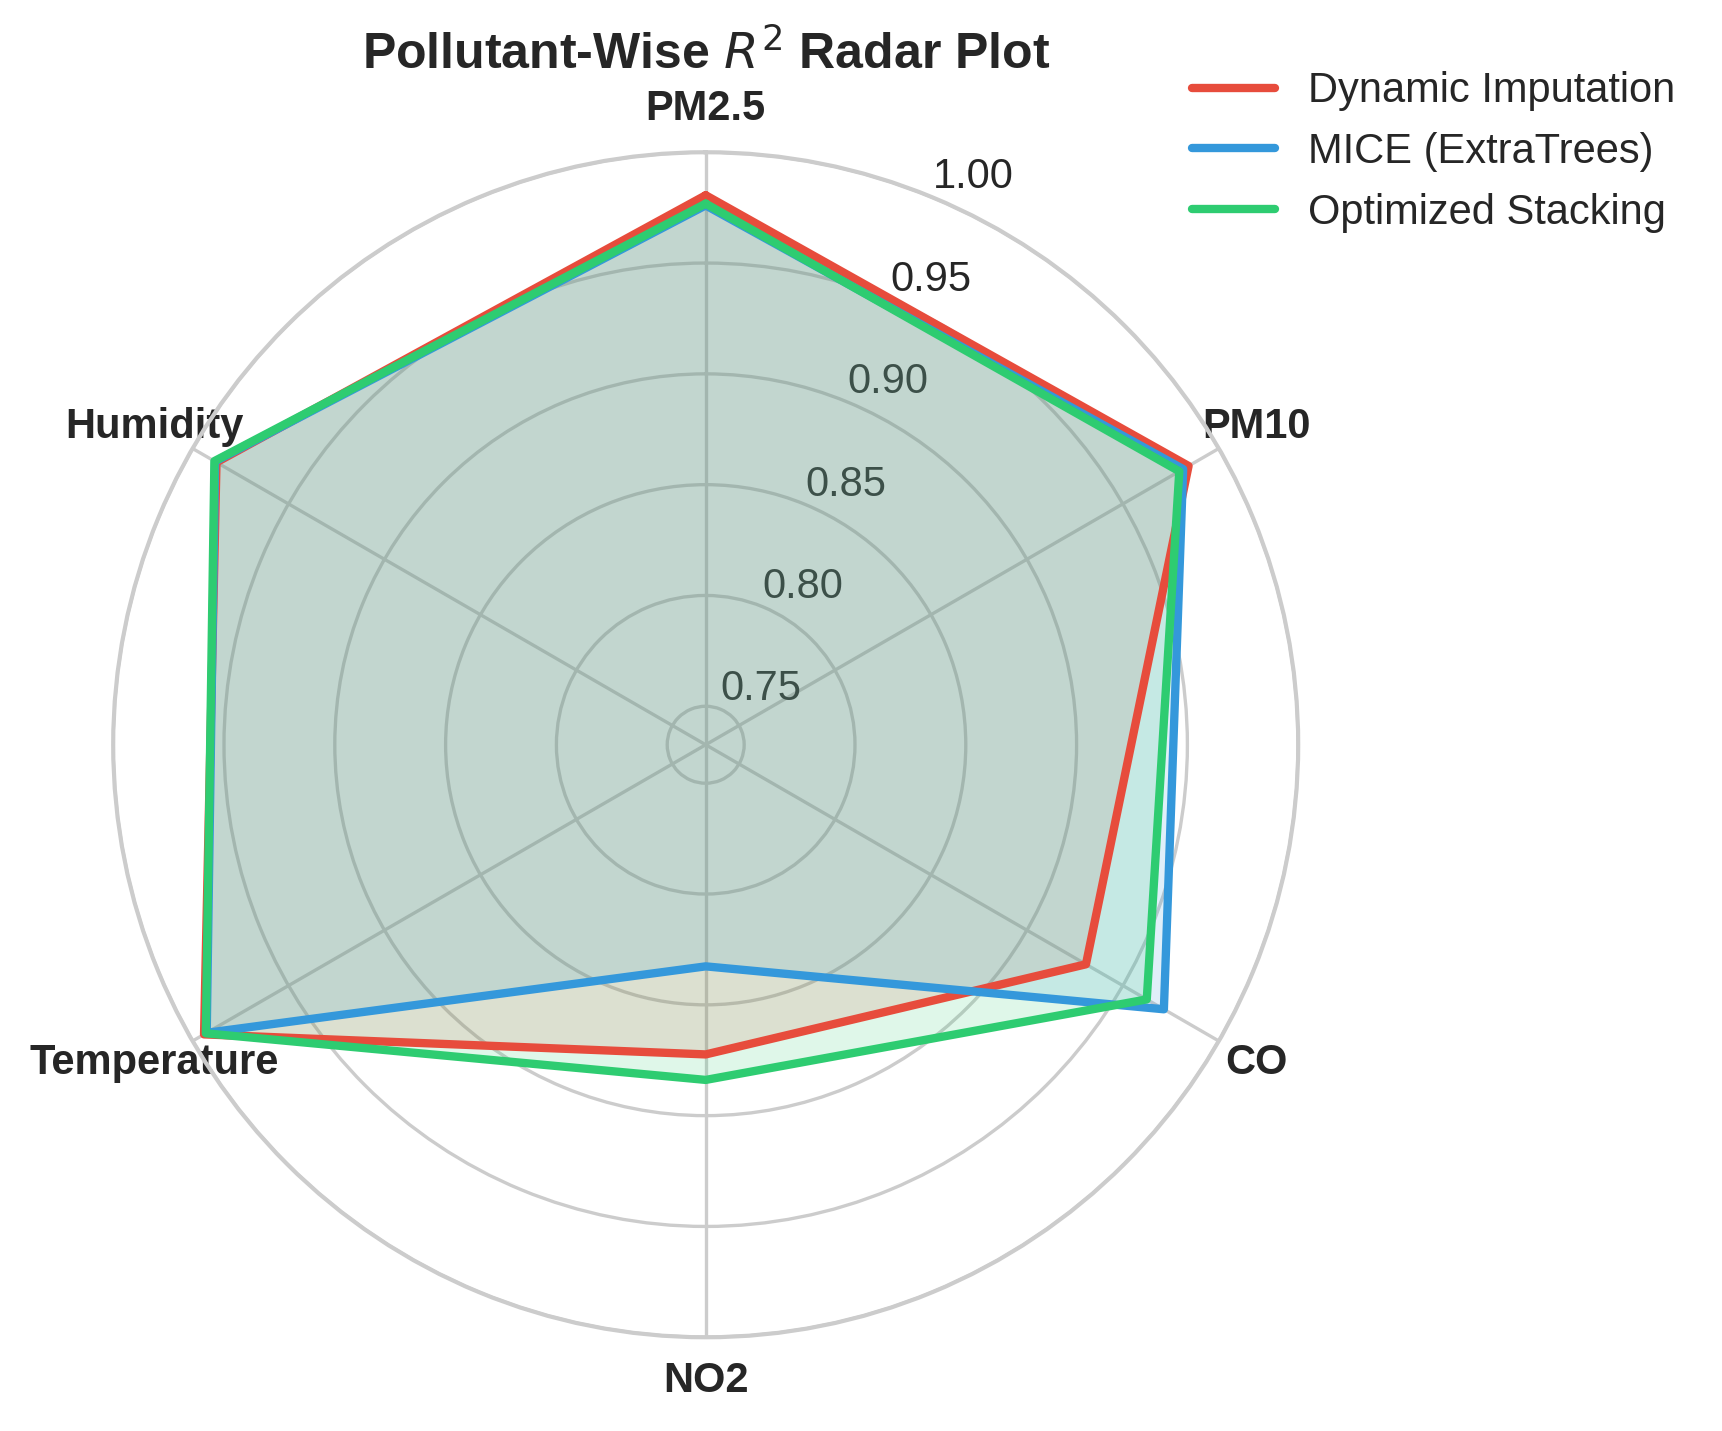

In [10]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

frameworks = ['Dynamic Imputation', 'MICE (ExtraTrees)', 'Optimized Stacking']

df_radar = pd.DataFrame(data_r2.T, index=pollutants, columns=frameworks)

num_vars = len(pollutants)
angles = np.linspace(0, 2 * np.pi, num_vars, endpoint=False).tolist()
angles += angles[:1]

fig, ax = plt.subplots(figsize=(6, 6), subplot_kw=dict(polar=True), dpi=300)
colors = ['#e74c3c', '#3498db', '#2ecc71']

for i, col in enumerate(frameworks):
    values = df_radar[col].values.tolist()
    values += values[:1]
    ax.plot(angles, values, color=colors[i], linewidth=2, label=col)
    ax.fill(angles, values, color=colors[i], alpha=0.15)

ax.set_theta_offset(np.pi / 2)
ax.set_theta_direction(-1)
ax.set_xticks(angles[:-1])
ax.set_xticklabels(pollutants, fontweight='bold', fontsize=10)
ax.set_ylim(max(0, data_r2.min() - 0.1), 1.0)

plt.title('Pollutant-Wise $R^2$ Radar Plot', fontweight='bold', fontsize=12, pad=20)
plt.legend(loc='upper right', bbox_to_anchor=(1.35, 1.1))

plt.tight_layout()
plt.savefig('figure3_radar_plot.png', bbox_inches='tight')
plt.show()

/tmp/ipykernel_23/4043676169.py:17: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(frameworks, rotation=15, ha='right', fontsize=9)
/tmp/ipykernel_23/4043676169.py:25: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(frameworks, rotation=15, ha='right', fontsize=9)
/tmp/ipykernel_23/4043676169.py:33: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[2].set_xticklabels(frameworks, rotation=15, ha='right', fontsize=9)


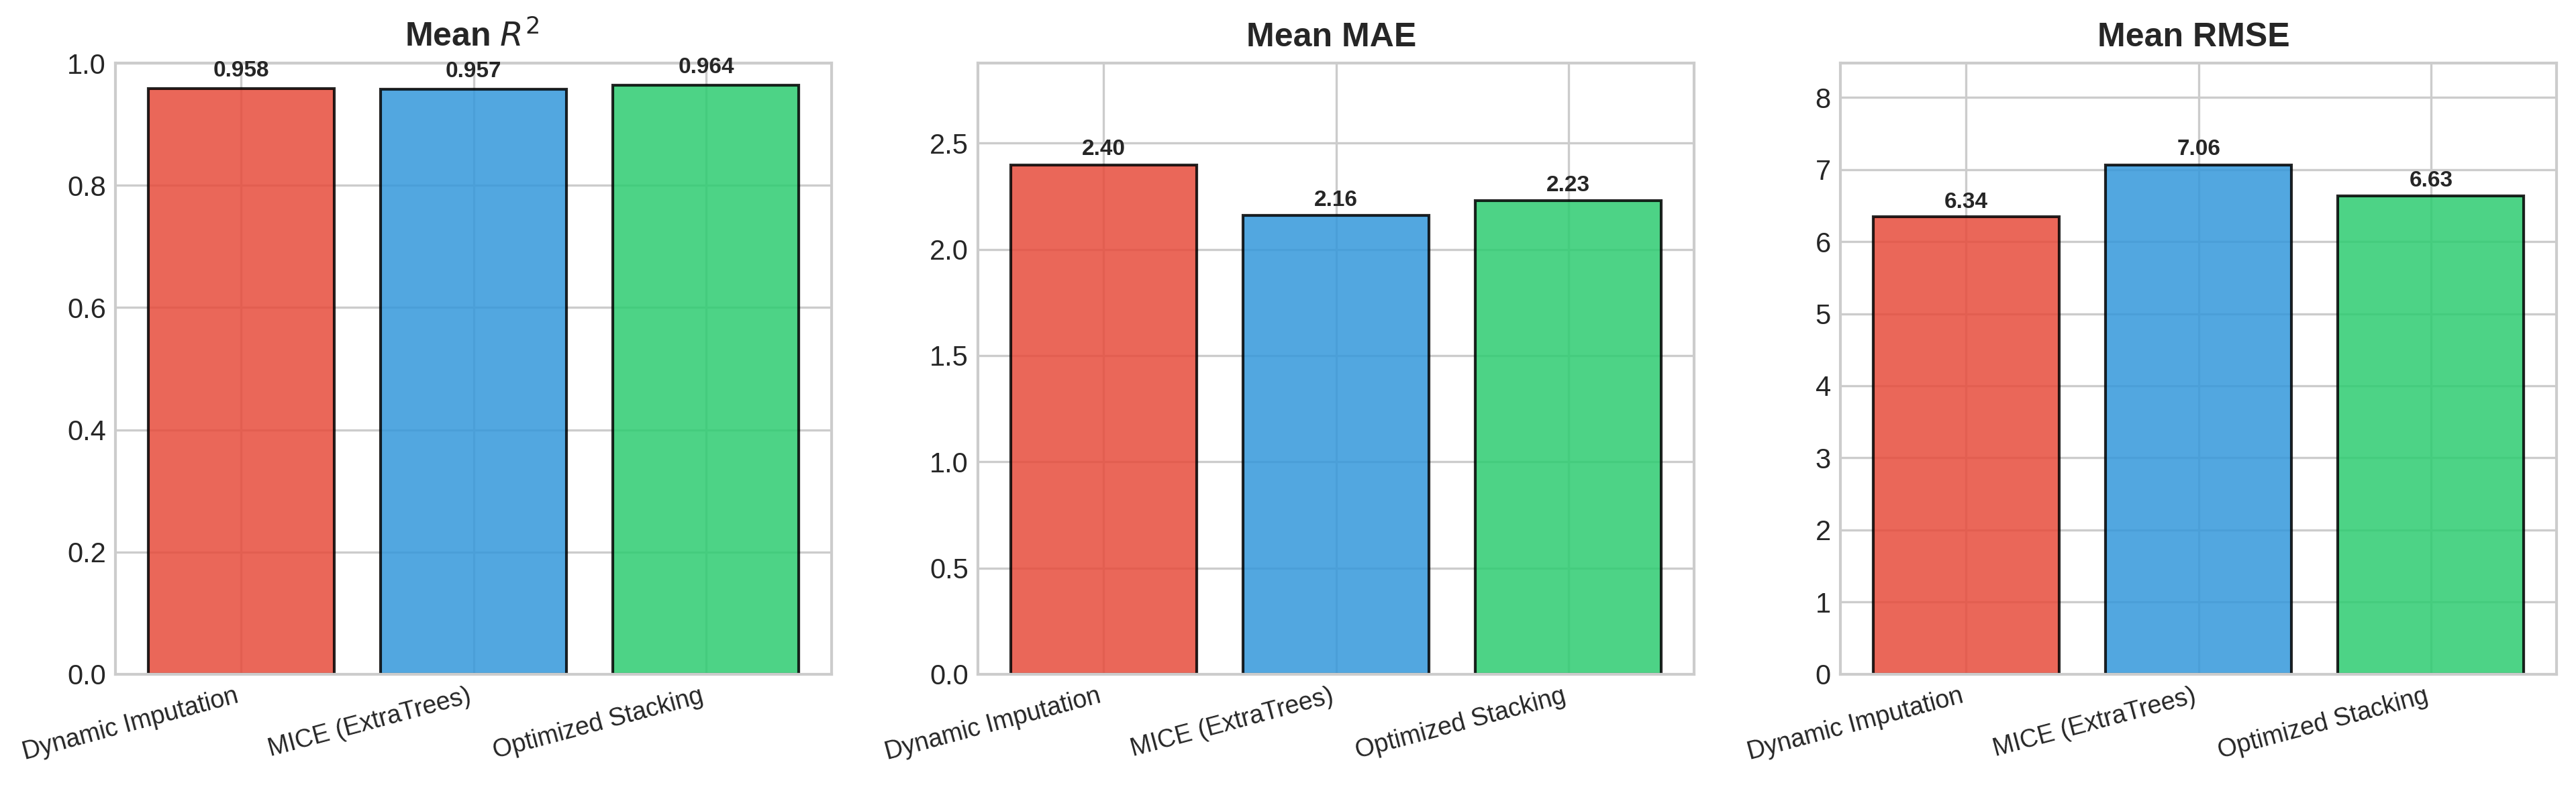

In [11]:
import matplotlib.pyplot as plt
import numpy as np

frameworks = ['Dynamic Imputation', 'MICE (ExtraTrees)', 'Optimized Stacking']
mean_r2 = summary_df['Mean R2'].tolist()
mean_mae = summary_df['Mean MAE'].tolist()
mean_rmse = summary_df['Mean RMSE'].tolist()

fig, axes = plt.subplots(1, 3, figsize=(13, 4), dpi=300)

colors = ['#e74c3c', '#3498db', '#2ecc71']


bars1 = axes[0].bar(frameworks, mean_r2, color=colors, edgecolor='black', alpha=0.85)
axes[0].set_title('Mean $R^2$ ', fontweight='bold')
axes[0].set_ylim(0, 1.0)
axes[0].set_xticklabels(frameworks, rotation=15, ha='right', fontsize=9)
for bar in bars1:
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02, f'{bar.get_height():.3f}', ha='center', fontweight='bold', fontsize=8)


bars2 = axes[1].bar(frameworks, mean_mae, color=colors, edgecolor='black', alpha=0.85)
axes[1].set_title('Mean MAE ', fontweight='bold')
axes[1].set_ylim(0, max(mean_mae) * 1.2)
axes[1].set_xticklabels(frameworks, rotation=15, ha='right', fontsize=9)
for bar in bars2:
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() * 1.02, f'{bar.get_height():.2f}', ha='center', fontweight='bold', fontsize=8)


bars3 = axes[2].bar(frameworks, mean_rmse, color=colors, edgecolor='black', alpha=0.85)
axes[2].set_title('Mean RMSE ', fontweight='bold')
axes[2].set_ylim(0, max(mean_rmse) * 1.2)
axes[2].set_xticklabels(frameworks, rotation=15, ha='right', fontsize=9)
for bar in bars3:
    axes[2].text(bar.get_x() + bar.get_width()/2, bar.get_height() * 1.02, f'{bar.get_height():.2f}', ha='center', fontweight='bold', fontsize=8)

plt.tight_layout()
plt.savefig('figure4_overall_metrics.png', bbox_inches='tight')
plt.show()